# Análisis exploratorio de rendimiento estudiantil — train completo

Este notebook analiza **todas las filas de train.csv**. No entrena modelos ni consulta validation.csv o test.csv.

## Alcance y precauciones
- El caso menciona bajo rendimiento en matemática y factores asociados. Analizamos GPA y los tres puntajes sin asumir que GPA deba ser el objetivo final.
- Las categorías GPA < 2.0, 2.0–<2.5 y >=2.5 son una hipótesis provisional, no criterios institucionales validados.
- Asociaciones y correlaciones no demuestran causalidad ni capacidad de anticipar un resultado futuro.
- Las variables sensibles se describen para auditar los datos; su presencia aquí no justifica incorporarlas como predictoras.
- No se borran automáticamente nulos, duplicados o valores extremos.

## Ejecución
Coloca este notebook en notebooks/ dentro de ModeloRiesgo. Selecciona el kernel .venv y ejecuta las celdas en orden. La primera importación a disco puede tardar y crea una base local adicional.

Dependencias: duckdb, pandas, numpy, matplotlib, seaborn, ipykernel.


In [1]:
from pathlib import Path
import os
import json
import time
import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 40)

candidates = [Path.cwd(), *Path.cwd().parents]
ROOT = next((p for p in candidates if (p / "data" / "train.csv").exists()), None)
if ROOT is None:
    raise FileNotFoundError("No se encuentra data/train.csv. Abre el notebook dentro del proyecto.")
TRAIN = ROOT / "data" / "train.csv"
REPORT = ROOT / "reports" / "eda_train"
CACHE = ROOT / "data" / "eda_cache"
REPORT.mkdir(parents=True, exist_ok=True)
CACHE.mkdir(parents=True, exist_ok=True)
print("Archivo:", TRAIN)
print("Tamaño GB:", round(TRAIN.stat().st_size / 1e9, 3))

con = duckdb.connect(str(CACHE / "train_eda.duckdb"))
con.execute("SET memory_limit='1GB'")
con.execute("SET threads=4")
con.execute("SET preserve_insertion_order=false")
temp = str(CACHE / "temp").replace("'", "''")
con.execute(f"SET temp_directory='{temp}'")

def qi(name):
    return '"' + name.replace('"', '""') + '"'

def save_table(frame, name):
    frame.to_csv(REPORT / f"{name}.csv", index=False)
    display(frame)

def save_plot(name):
    plt.tight_layout()
    plt.savefig(REPORT / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()


Archivo: c:\Users\gpatr\Desktop\ModeloRiesgo\data\train.csv
Tamaño GB: 1.329


## 1. Importación completa con caché en disco
Se importa el CSV completo como texto para detectar valores que no se puedan convertir a números. No se omiten filas defectuosas silenciosamente. Si la lectura falla, debe investigarse el formato del archivo.

La base en disco y sus temporales requieren espacio adicional. El límite de memoria reduce el uso del motor, pero no es un límite absoluto de todo el proceso Python. Si falta memoria o espacio, no continúes a ciegas: reduce threads o aumenta el límite según tu equipo.


In [2]:
fingerprint = {"path": str(TRAIN.resolve()), "bytes": TRAIN.stat().st_size,
               "mtime_ns": TRAIN.stat().st_mtime_ns}
meta_path = CACHE / "source_metadata.json"
cached = json.loads(meta_path.read_text()) if meta_path.exists() else None
exists = con.execute("SELECT count(*) FROM information_schema.tables WHERE table_name='raw'").fetchone()[0]
REBUILD = False
if REBUILD or not exists or cached != fingerprint:
    start = time.perf_counter()
    print("Importando todo train.csv. Espera a que termine...", flush=True)
    con.execute("DROP TABLE IF EXISTS train")
    con.execute("DROP TABLE IF EXISTS raw")
    con.execute("CREATE TABLE raw AS SELECT * FROM read_csv(?, header=true, all_varchar=true, sample_size=-1)", [str(TRAIN)])
    meta_path.write_text(json.dumps(fingerprint, indent=2))
    print("Importación finalizada. Segundos:", round(time.perf_counter()-start, 1))
else:
    print("Reutilizando caché del mismo archivo.")

schema = con.execute("DESCRIBE raw").df()
N = con.execute("SELECT count(*) FROM raw").fetchone()[0]
print(f"Filas reales analizadas: {N:,}")
save_table(schema, "esquema_original")
display(con.execute("SELECT * FROM raw LIMIT 5").df())


Importando todo train.csv. Espera a que termine...
Importación finalizada. Segundos: 31.1
Filas reales analizadas: 8,000,774


,column_name,column_type,null,key,default,extra
0,Age,VARCHAR,YES,None,None,None
1,Grade,VARCHAR,YES,None,None,None
2,Gender,VARCHAR,YES,None,None,None
3,Race,VARCHAR,YES,None,None,None
4,SES_Quartile,VARCHAR,YES,None,None,None
5,ParentalEducation,VARCHAR,YES,None,None,None
6,SchoolType,VARCHAR,YES,None,None,None
7,Locale,VARCHAR,YES,None,None,None
8,TestScore_Math,VARCHAR,YES,None,None,None
9,TestScore_Reading,VARCHAR,YES,None,None,None


,Age,Grade,Gender,Race,SES_Quartile,ParentalEducation,SchoolType,Locale,TestScore_Math,TestScore_Reading,TestScore_Science,GPA,AttendanceRate,StudyHours,InternetAccess,Extracurricular,PartTimeJob,ParentSupport,Romantic,FreeTime,GoOut
0,16,11,Male,Hispanic,4,SomeCollege,Public,Suburban,91.56247989745472,80.75627340948574,92.3624604433968,3.4789068901079623,0.9672380663006862,1.185309116893712,1,1,0,1,0,5,3
1,17,12,Male,White,4,SomeCollege,Private,Rural,96.75513868006944,93.03322994268206,99.87372378529211,4.0,1.0,1.2362724703695385,1,0,0,0,0,3,4
2,17,12,Female,Black,4,Bachelors+,Private,Rural,60.19739480309406,70.87614762662959,61.85590003743586,2.457760915526716,0.859485075636242,0.6936071637856652,1,1,0,1,1,2,2
3,14,9,Female,White,1,<HS,Public,City,84.0836285940226,76.85353733906848,71.05332217384766,3.134948623974706,0.9103862918562023,1.1412184161914227,1,1,0,0,0,3,1
4,16,11,Female,Other,4,<HS,Public,City,70.00470719432136,63.811822930215634,72.15950551911587,3.047136298490944,0.8928402058565739,0.9137103411520316,1,0,0,0,0,2,3


In [3]:
NUMERIC = ["Age", "Grade", "SES_Quartile", "TestScore_Math", "TestScore_Reading",
           "TestScore_Science", "GPA", "AttendanceRate", "StudyHours", "InternetAccess",
           "Extracurricular", "PartTimeJob", "ParentSupport", "Romantic", "FreeTime", "GoOut"]
CATEGORICAL = ["Gender", "Race", "ParentalEducation", "SchoolType", "Locale"]
RANGES = {"Age": (14,18), "Grade": (9,12), "SES_Quartile": (1,4),
          "TestScore_Math": (0,100), "TestScore_Reading": (0,100),
          "TestScore_Science": (0,100), "GPA": (0,4), "AttendanceRate": (.70,1),
          "StudyHours": (0,4), "InternetAccess": (0,1), "Extracurricular": (0,1),
          "PartTimeJob": (0,1), "ParentSupport": (0,1), "Romantic": (0,1),
          "FreeTime": (1,5), "GoOut": (1,5)}
INTEGER = {"Age", "Grade", "SES_Quartile", "InternetAccess", "Extracurricular",
           "PartTimeJob", "ParentSupport", "Romantic", "FreeTime", "GoOut"}
columns = schema["column_name"].tolist()
missing = set(NUMERIC + CATEGORICAL) - set(columns)
if missing:
    raise ValueError(f"Faltan columnas esperadas: {sorted(missing)}")
print("Columnas adicionales:", sorted(set(columns)-set(NUMERIC+CATEGORICAL)))
quality = []
for col in columns:
    c = qi(col)
    blank = f"({c} IS NULL OR trim({c})='')"
    nmiss = con.execute(f"SELECT count(*) FROM raw WHERE {blank}").fetchone()[0]
    row = {"variable": col, "nulos_o_vacios": nmiss, "porcentaje": 100*nmiss/N}
    if col in NUMERIC:
        x = f"try_cast({c} AS DOUBLE)"
        lo, hi = RANGES[col]
        row["no_convertibles"] = con.execute(f"SELECT count(*) FROM raw WHERE NOT {blank} AND {x} IS NULL").fetchone()[0]
        row["fuera_de_rango_o_no_finitos"] = con.execute(f"SELECT count(*) FROM raw WHERE {x} IS NOT NULL AND (NOT isfinite({x}) OR {x} < {lo} OR {x} > {hi})").fetchone()[0]
        if col in INTEGER:
            row["no_enteros"] = con.execute(f"SELECT count(*) FROM raw WHERE isfinite({x}) AND {x} != floor({x})").fetchone()[0]
    quality.append(row)
quality = pd.DataFrame(quality)
save_table(quality, "calidad_datos")

# No se imputan ni recortan valores. Solo se tipifican; no finitos pasan a NULL.
expressions = []
for col in NUMERIC:
    x = f"try_cast({qi(col)} AS DOUBLE)"
    expressions.append(f"CASE WHEN isfinite({x}) THEN {x} END AS {qi(col)}")
for col in CATEGORICAL:
    expressions.append(f"NULLIF(trim({qi(col)}), '') AS {qi(col)}")
con.execute("CREATE OR REPLACE VIEW typed AS SELECT " + ", ".join(expressions) + " FROM raw")


Columnas adicionales: []


,variable,nulos_o_vacios,porcentaje,no_convertibles,fuera_de_rango_o_no_finitos,no_enteros
0,Age,0,0.0,0.0,0.0,0.0
1,Grade,0,0.0,0.0,0.0,0.0
2,Gender,0,0.0,NaN,NaN,NaN
3,Race,0,0.0,NaN,NaN,NaN
4,SES_Quartile,0,0.0,0.0,0.0,0.0
5,ParentalEducation,0,0.0,NaN,NaN,NaN
6,SchoolType,0,0.0,NaN,NaN,NaN
7,Locale,0,0.0,NaN,NaN,NaN
8,TestScore_Math,0,0.0,0.0,0.0,NaN
9,TestScore_Reading,0,0.0,0.0,0.0,NaN


## 2. Estadísticos de todas las filas
Los cuantiles se calculan sobre todos los valores numéricos válidos, no sobre una muestra. Se procesa una variable por consulta para reducir picos de memoria. Los valores fuera del rango documentado se reportan pero no se eliminan automáticamente.


In [4]:
rows = []
for col in NUMERIC:
    c = qi(col)
    print("Resumen:", col, flush=True)
    result = con.execute(f"""SELECT count({c}), avg({c}), stddev_samp({c}),
        min({c}), quantile_cont({c}, 0.25), median({c}),
        quantile_cont({c}, 0.75), max({c}) FROM typed""").fetchone()
    rows.append(dict(zip(["variable", "n_validos", "media", "desv_est", "min", "q1", "mediana", "q3", "max"], [col, *result])))
summary = pd.DataFrame(rows)
save_table(summary, "resumen_numerico_completo")


Resumen: Age
Resumen: Grade
Resumen: SES_Quartile
Resumen: TestScore_Math
Resumen: TestScore_Reading
Resumen: TestScore_Science
Resumen: GPA
Resumen: AttendanceRate
Resumen: StudyHours
Resumen: InternetAccess
Resumen: Extracurricular
Resumen: PartTimeJob
Resumen: ParentSupport
Resumen: Romantic
Resumen: FreeTime
Resumen: GoOut


,variable,n_validos,media,desv_est,min,q1,mediana,q3,max
0,Age,8000774,15.999591,1.413915,14.000000,15.000000,16.000000,17.000000,18.000000
1,Grade,8000774,10.799739,1.165974,9.000000,10.000000,11.000000,12.000000,12.000000
2,SES_Quartile,8000774,2.499802,1.118161,1.000000,1.000000,3.000000,3.000000,4.000000
3,TestScore_Math,8000774,74.975542,9.944944,22.576813,68.246988,74.995312,81.741983,100.000000
4,TestScore_Reading,8000774,74.978937,9.943306,21.187972,68.252674,75.002107,81.743341,100.000000
5,TestScore_Science,8000774,74.978513,9.948554,19.188829,68.255227,75.001765,81.741739,100.000000
6,GPA,8000774,2.996743,0.459513,0.713181,2.685036,2.999824,3.314440,4.000000
7,AttendanceRate,8000774,0.899589,0.048062,0.700000,0.866952,0.899978,0.933040,1.000000
8,StudyHours,8000774,0.999726,0.348109,0.000000,0.764208,0.999894,1.235127,2.793829
9,InternetAccess,8000774,0.849827,0.357241,0.000000,1.000000,1.000000,1.000000,1.000000


Gender


,categoria,n,porcentaje
0,Female,4080208,50.997666
1,Male,3920566,49.002334


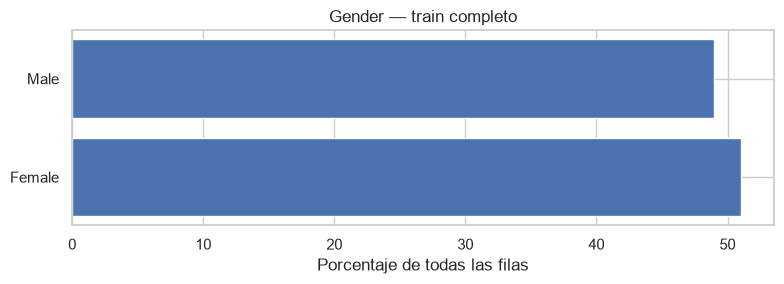

Race


,categoria,n,porcentaje
0,White,3519522,43.989769
1,Hispanic,2319159,28.986683
2,Black,1200976,15.010748
3,Two-or-more,400991,5.011903
4,Asian,400754,5.008940
5,Other,159372,1.991957


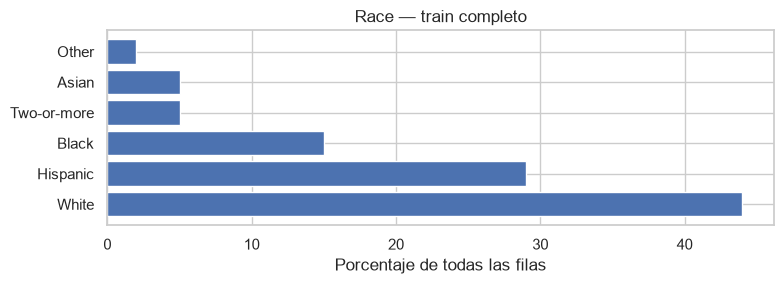

ParentalEducation


,categoria,n,porcentaje
0,HS,2601118,32.510830
1,SomeCollege,2400823,30.007384
2,Bachelors+,1500310,18.752061
3,<HS,1498523,18.729725


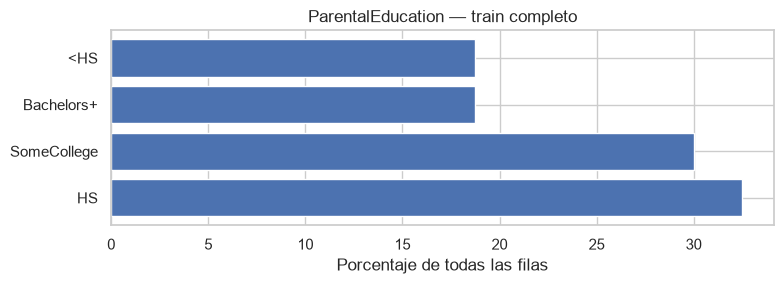

SchoolType


,categoria,n,porcentaje
0,Public,6760300,84.495575
1,Private,1240474,15.504425


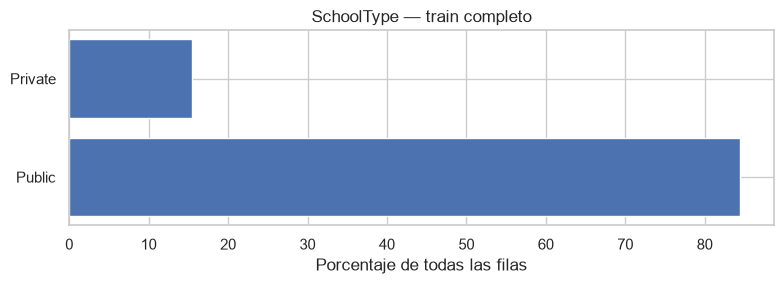

Locale


,categoria,n,porcentaje
0,Suburban,3120675,39.004664
1,City,2479888,30.995601
2,Rural,1520189,19.000524
3,Town,880022,10.999211


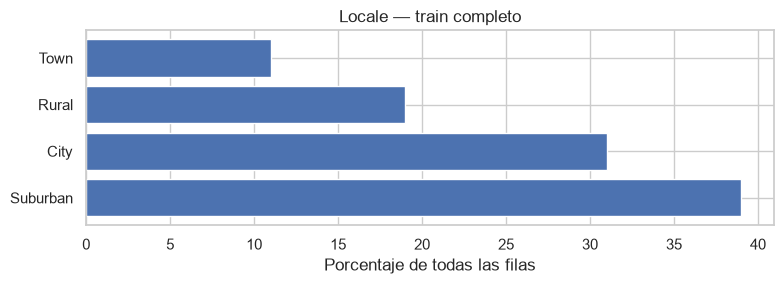

InternetAccess


,categoria,n,porcentaje
0,1.0,6799271,84.982665
1,0.0,1201503,15.017335


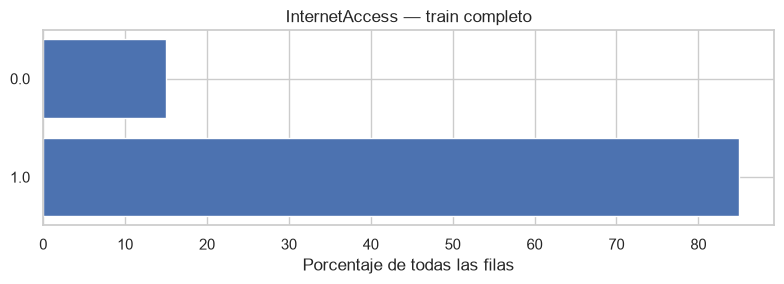

Extracurricular


,categoria,n,porcentaje
0,1.0,4400178,54.996904
1,0.0,3600596,45.003096


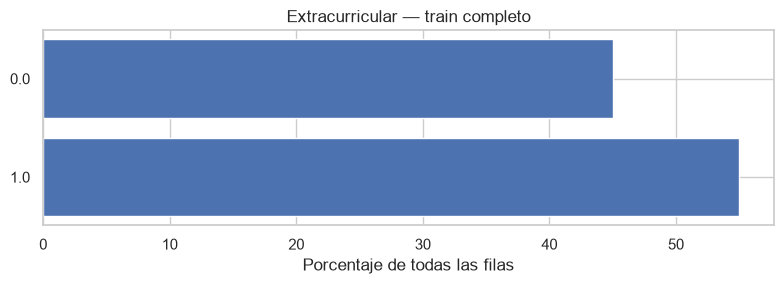

PartTimeJob


,categoria,n,porcentaje
0,0.0,6561447,82.010153
1,1.0,1439327,17.989847


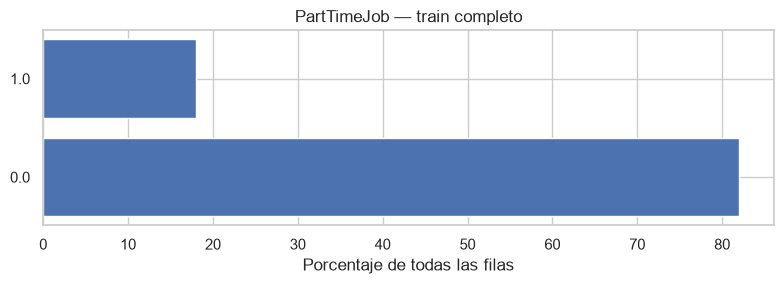

ParentSupport


,categoria,n,porcentaje
0,0.0,4613756,57.666371
1,1.0,3387018,42.333629


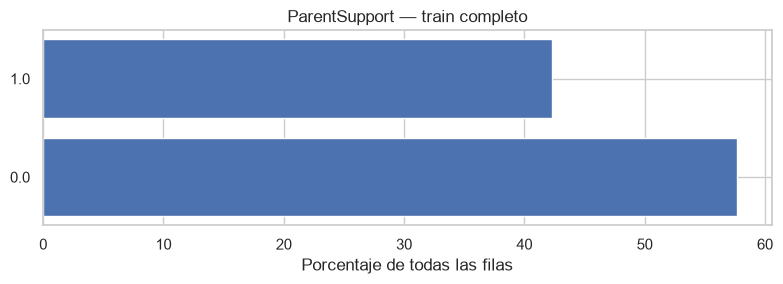

Romantic


,categoria,n,porcentaje
0,0.0,6401859,80.015496
1,1.0,1598915,19.984504


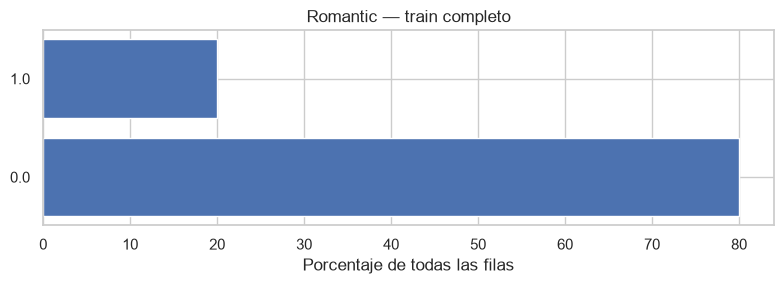

In [5]:
for col in CATEGORICAL + ["InternetAccess", "Extracurricular", "PartTimeJob", "ParentSupport", "Romantic"]:
    c = qi(col)
    table = con.execute(f"SELECT {c} AS categoria, count(*) AS n FROM typed GROUP BY {c} ORDER BY n DESC").df()
    table["porcentaje"] = 100*table["n"]/N
    print(col)
    table.to_csv(REPORT / f"frecuencias_{col}.csv", index=False)
    display(table)
    plt.figure(figsize=(8,3))
    plt.barh(table["categoria"].fillna("NULO").astype(str), table["porcentaje"])
    plt.xlabel("Porcentaje de todas las filas")
    plt.title(col + " — train completo")
    save_plot("frecuencias_" + col)


## 3. Histogramas exactos por intervalos
Cada barra cuenta todas las filas que caen en ese intervalo. Los registros nulos o fuera de rango no se muestran en el histograma; se pueden revisar en la tabla de calidad. No se muestrean puntos.


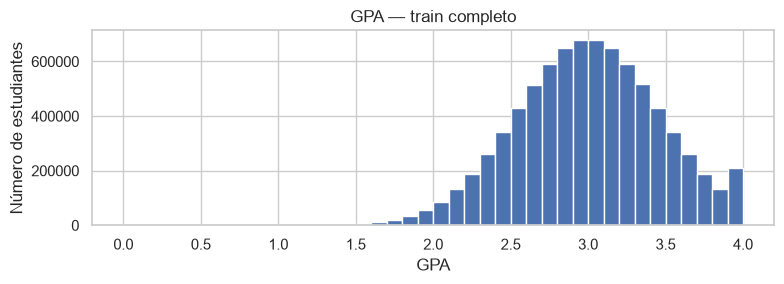

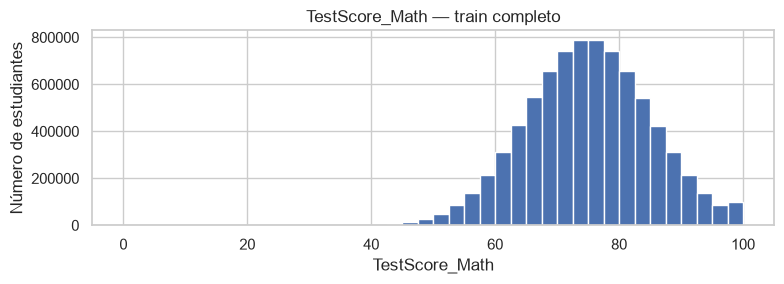

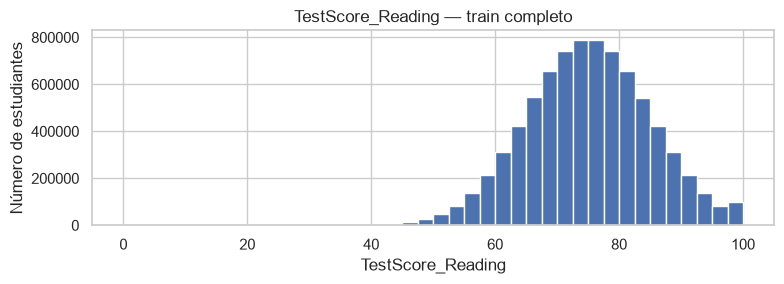

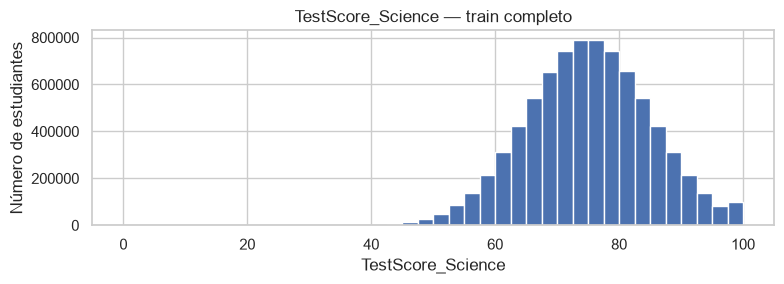

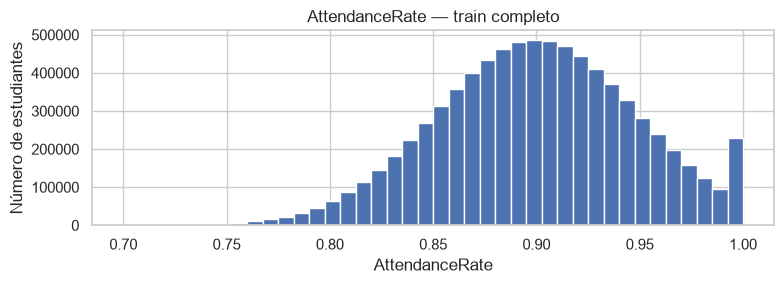

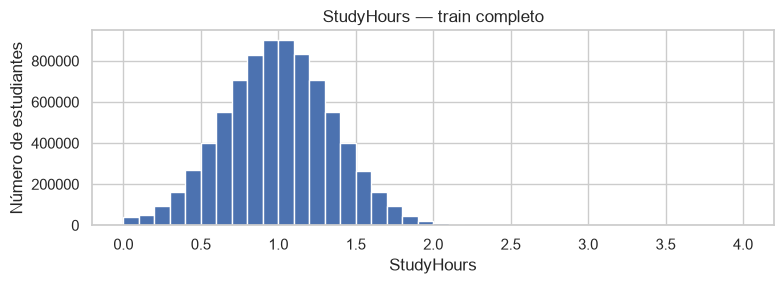

In [6]:
PLOT_NUM = ["GPA", "TestScore_Math", "TestScore_Reading", "TestScore_Science", "AttendanceRate", "StudyHours"]
for col in PLOT_NUM:
    lo, hi = RANGES[col]
    bins = 40
    width = (hi-lo)/bins
    c = qi(col)
    h = con.execute(f"""SELECT least({bins-1}, floor(({c}-{lo})/{width}))::INTEGER AS bin,
        count(*) AS n FROM typed WHERE {c} BETWEEN {lo} AND {hi}
        GROUP BY bin ORDER BY bin""").df()
    counts = h.set_index("bin")["n"].reindex(range(bins), fill_value=0)
    plt.figure(figsize=(8,3))
    plt.bar(lo + np.arange(bins)*width, counts.values, width=width, align="edge", edgecolor="white")
    plt.xlabel(col)
    plt.ylabel("Número de estudiantes")
    plt.title(col + " — train completo")
    h.to_csv(REPORT / f"histograma_{col}.csv", index=False)
    save_plot("histograma_"+col)


## 4. Boxplots con cuartiles y bigotes calculados sobre train completo
Los límites de Tukey son Q1−1.5×IQR y Q3+1.5×IQR. Se cuentan todos los registros fuera de estos límites. No se dibujan millones de puntos extremos: su cantidad y porcentaje se reportan en una tabla.

Un valor extremo estadístico no es necesariamente un error. En educación puede corresponder precisamente a estudiantes relevantes para el análisis. Los boxplots no justifican eliminarlos automáticamente.


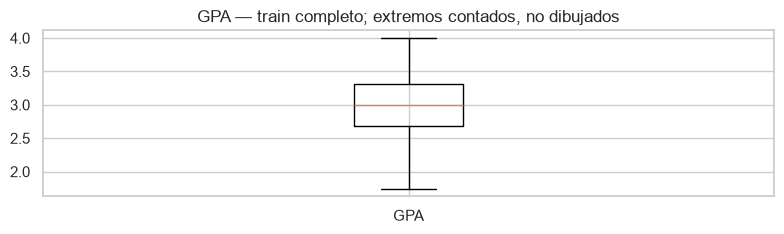

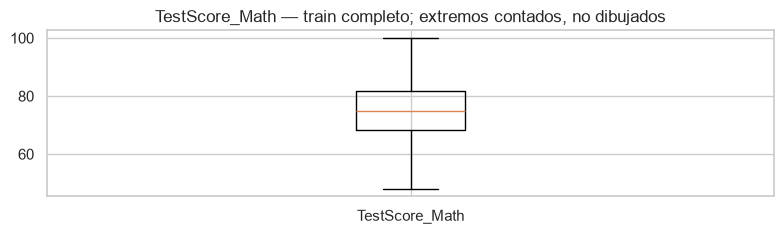

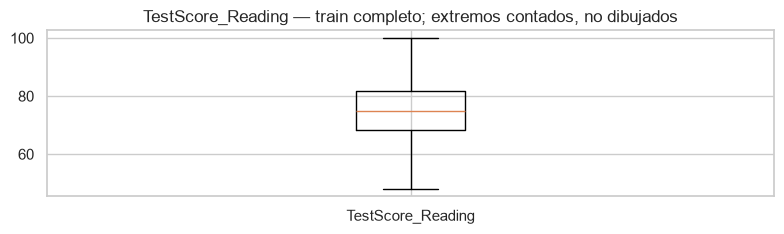

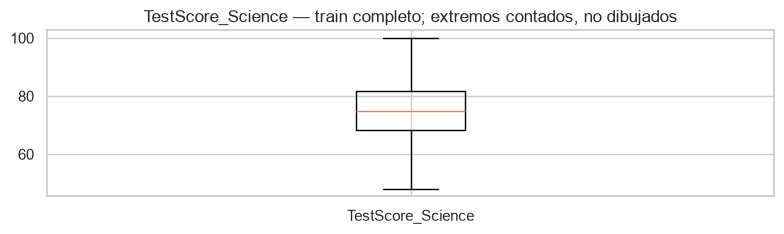

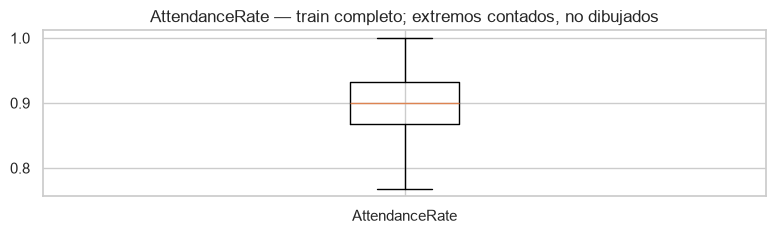

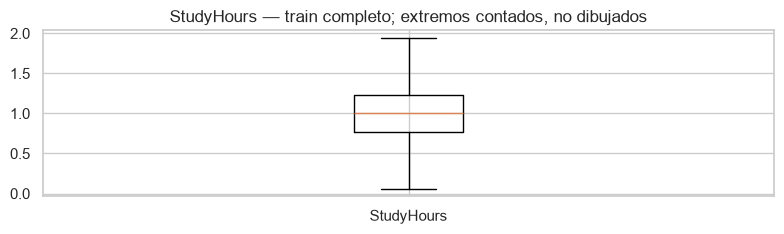

,variable,limite_inferior,limite_superior,n_extremos,porcentaje_validos
0,GPA,1.740930,4.258545,28051,0.350604
1,TestScore_Math,48.004497,101.984474,27806,0.347541
2,TestScore_Reading,48.016674,101.979341,27999,0.349954
3,TestScore_Science,48.025459,101.971507,28051,0.350604
4,AttendanceRate,0.767820,1.032172,28127,0.351553
5,StudyHours,0.057830,1.941506,54620,0.682684


In [7]:
box_rows = []
for col in PLOT_NUM:
    stats = summary.set_index("variable").loc[col]
    q1, q3 = stats["q1"], stats["q3"]
    low, high = q1-1.5*(q3-q1), q3+1.5*(q3-q1)
    c = qi(col)
    wlo, whi, out = con.execute(f"""SELECT
        min({c}) FILTER (WHERE {c} BETWEEN {low} AND {high}),
        max({c}) FILTER (WHERE {c} BETWEEN {low} AND {high}),
        count(*) FILTER (WHERE {c} < {low} OR {c} > {high}) FROM typed""").fetchone()
    box_rows.append({"variable":col, "limite_inferior":low, "limite_superior":high,
                     "n_extremos":out, "porcentaje_validos":100*out/stats["n_validos"]})
    fig, ax = plt.subplots(figsize=(8,2.5))
    ax.bxp([{"label":col, "q1":q1, "med":stats["mediana"], "q3":q3,
             "whislo":wlo, "whishi":whi, "fliers":[]}], showfliers=False)
    ax.set_title(f"{col} — train completo; extremos contados, no dibujados")
    save_plot("boxplot_"+col)
save_table(pd.DataFrame(box_rows), "extremos_tukey")


## 5. Correlación de Pearson usando todas las parejas válidas
Cada correlación usa todas las filas donde ambas variables tienen valores numéricos finitos. Una asociación no es un efecto causal. La ausencia de correlación lineal tampoco descarta relaciones no lineales. Las variables constantes producen correlaciones indefinidas.


Calculando correlaciones sobre todas las filas...


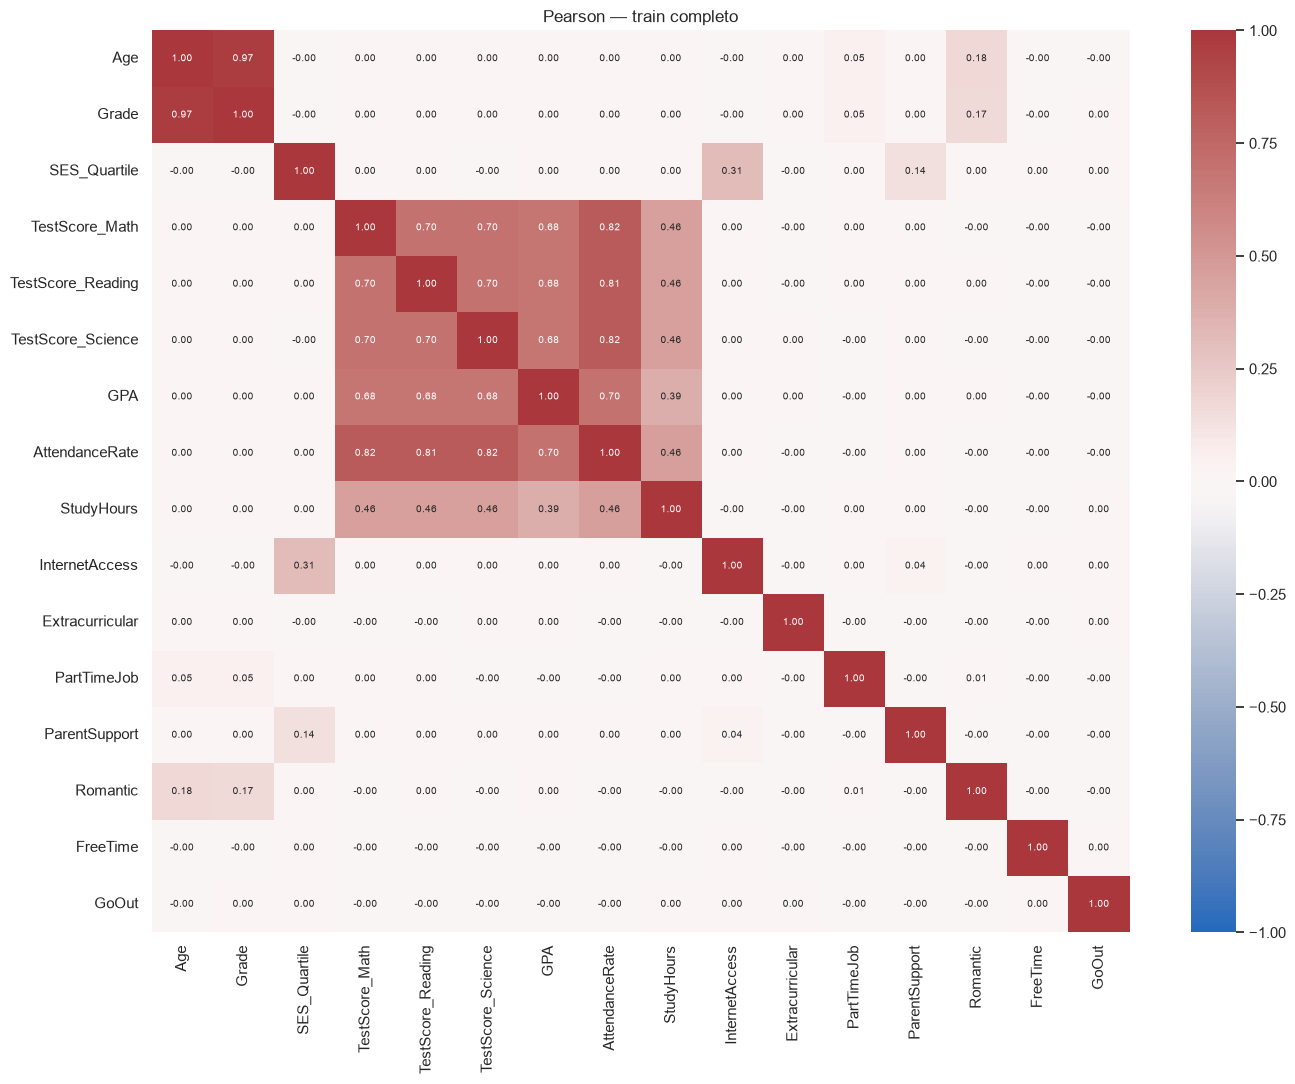

,GPA,TestScore_Math
GPA,1.000000,0.683268
AttendanceRate,0.696722,0.815022
TestScore_Reading,0.683433,0.699794
TestScore_Science,0.683300,0.699755
TestScore_Math,0.683268,1.000000
StudyHours,0.389857,0.456327
Age,0.000849,0.000629
Grade,0.000840,0.000636
InternetAccess,0.000655,0.000318
Extracurricular,0.000435,-0.000199


In [8]:
CORR_COLS = NUMERIC
pairs = [(a,b) for i,a in enumerate(CORR_COLS) for b in CORR_COLS[i:]]
expressions = [f"corr({qi(a)}, {qi(b)}) AS c{i}" for i,(a,b) in enumerate(pairs)]
print("Calculando correlaciones sobre todas las filas...", flush=True)
values = con.execute("SELECT " + ", ".join(expressions) + " FROM typed").fetchone()
corr = pd.DataFrame(np.nan, index=CORR_COLS, columns=CORR_COLS)
for (a,b), v in zip(pairs, values):
    corr.loc[a,b] = corr.loc[b,a] = v
corr.to_csv(REPORT / "correlacion_pearson_completa.csv")
plt.figure(figsize=(14,11))
sns.heatmap(corr, cmap="vlag", center=0, vmin=-1, vmax=1, annot=True, fmt=".2f", annot_kws={"size":7})
plt.title("Pearson — train completo")
save_plot("mapa_correlaciones")
display(corr[["GPA", "TestScore_Math"]].sort_values("GPA", ascending=False))


## 6. Relación con desempeño: agregados de todas las filas
Las medias por grupo son descriptivas: no controlan confusores, no prueban causas y pueden ocultar diferencias de distribución. Los grupos pequeños requieren especial cautela.


ParentSupport


,grupo,n,n_gpa,gpa_medio,math_medio,asistencia_media
0,0.0,4613756,4613756,2.996669,74.971679,0.899575
1,1.0,3387018,3387018,2.996843,74.980804,0.899609


InternetAccess


,grupo,n,n_gpa,gpa_medio,math_medio,asistencia_media
0,0.0,1201503,1201503,2.996026,74.968017,0.899545
1,1.0,6799271,6799271,2.996870,74.976871,0.899597


PartTimeJob


,grupo,n,n_gpa,gpa_medio,math_medio,asistencia_media
0,0.0,6561447,6561447,2.996759,74.974554,0.899589
1,1.0,1439327,1439327,2.996669,74.980044,0.899588


... (4 outputs left out)

SchoolType


,grupo,n,n_gpa,gpa_medio,math_medio,asistencia_media
0,Private,1240474,1240474,2.996944,74.986484,0.899625
1,Public,6760300,6760300,2.996706,74.973534,0.899583


Locale


,grupo,n,n_gpa,gpa_medio,math_medio,asistencia_media
0,City,2479888,2479888,2.996783,74.974041,0.899599
1,Rural,1520189,1520189,2.996767,74.981340,0.899582
2,Suburban,3120675,3120675,2.996659,74.975454,0.899579
3,Town,880022,880022,2.996886,74.970066,0.899608


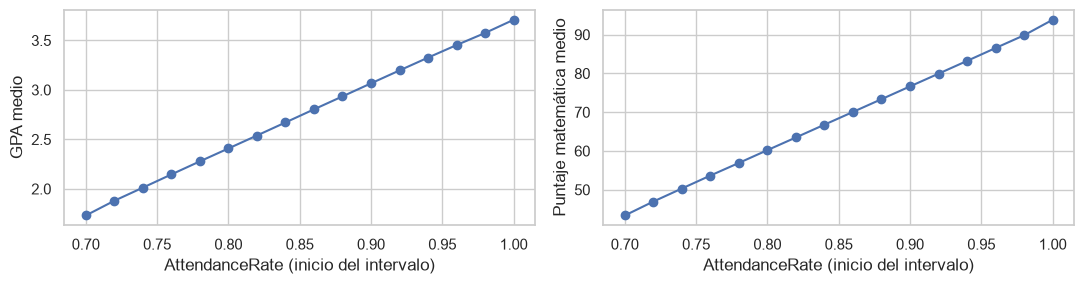

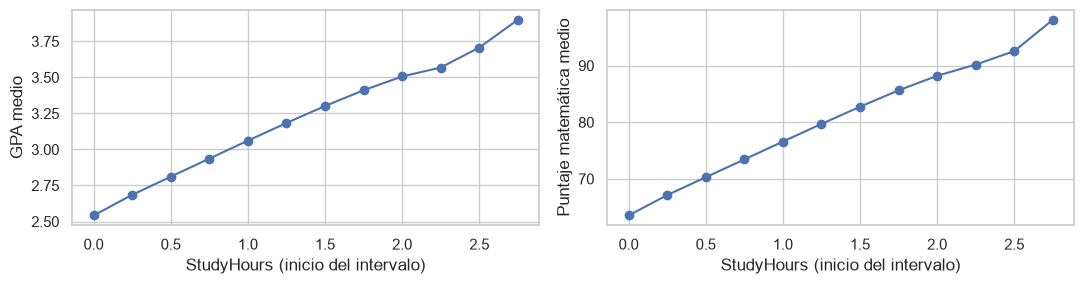

In [9]:
for col in ["ParentSupport", "InternetAccess", "PartTimeJob", "SES_Quartile", "ParentalEducation", "SchoolType", "Locale"]:
    c = qi(col)
    table = con.execute(f"""SELECT {c} AS grupo, count(*) AS n,
        count(GPA) AS n_gpa, avg(GPA) AS gpa_medio,
        avg(TestScore_Math) AS math_medio, avg(AttendanceRate) AS asistencia_media
        FROM typed GROUP BY {c} ORDER BY {c}""").df()
    print(col)
    save_table(table, "desempeno_por_"+col)

for col, step in [("AttendanceRate", .02), ("StudyHours", .25)]:
    c = qi(col)
    table = con.execute(f"""SELECT floor({c}/{step})*{step} AS inicio_intervalo,
        count(*) AS n, avg(GPA) AS gpa_medio, avg(TestScore_Math) AS math_medio
        FROM typed WHERE {c} IS NOT NULL GROUP BY inicio_intervalo ORDER BY inicio_intervalo""").df()
    table.to_csv(REPORT / f"desempeno_intervalos_{col}.csv", index=False)
    fig, axes = plt.subplots(1,2,figsize=(11,3))
    axes[0].plot(table.inicio_intervalo, table.gpa_medio, marker="o")
    axes[0].set_ylabel("GPA medio")
    axes[1].plot(table.inicio_intervalo, table.math_medio, marker="o")
    axes[1].set_ylabel("Puntaje matemática medio")
    for ax in axes:
        ax.set_xlabel(col + " (inicio del intervalo)")
    save_plot("relacion_"+col)


## 7. Auditoría de las categorías provisionales de GPA
No se ajustan los umbrales para maximizar accuracy ni para equilibrar artificialmente clases. Los registros fuera de 0–4 o nulos se reportan como no clasificables, no como sin riesgo.

“Sin riesgo” aquí significa únicamente GPA >=2.5 según esta regla, no ausencia de otras necesidades. Si la tarea finalmente trata matemática, esta etiqueta debe revisarse antes de entrenar.


,nivel_riesgo,n,porcentaje
0,sin_riesgo,6863200,85.781701
1,riesgo_medio,1008803,12.608818
2,riesgo_alto,128771,1.609482


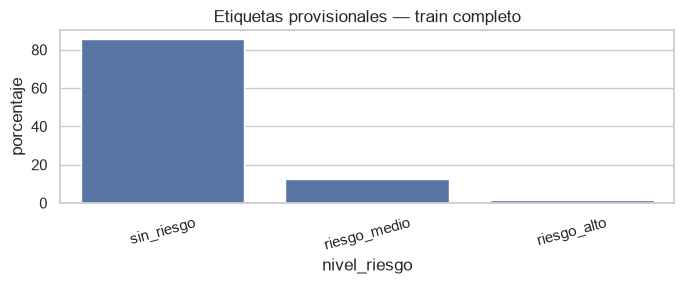

,nivel_riesgo,n,asistencia_hasta_85,asistencia_media,estudio_medio
0,riesgo_alto,128771,107484,0.814300,0.659223
1,riesgo_medio,1008803,506635,0.849747,0.799034
2,sin_riesgo,6863200,616666,0.908516,1.035614


El 85% se usa solo como contraste exploratorio; no se afirma que defina una norma de este dataset.


In [10]:
HIGH = 2.0
MEDIUM = 2.5
risk_sql = f"""CASE WHEN GPA IS NULL OR GPA < 0 OR GPA > 4 THEN 'no_clasificable'
    WHEN GPA < {HIGH} THEN 'riesgo_alto'
    WHEN GPA < {MEDIUM} THEN 'riesgo_medio'
    ELSE 'sin_riesgo' END"""
con.execute("CREATE OR REPLACE VIEW risk AS SELECT *, " + risk_sql + " AS nivel_riesgo FROM typed")
distribution = con.execute("SELECT nivel_riesgo, count(*) AS n FROM risk GROUP BY nivel_riesgo ORDER BY n DESC").df()
distribution["porcentaje"] = 100*distribution.n/N
save_table(distribution, "distribucion_riesgo_gpa_provisional")
plt.figure(figsize=(7,3))
sns.barplot(data=distribution, x="nivel_riesgo", y="porcentaje")
plt.xticks(rotation=15)
plt.title("Etiquetas provisionales — train completo")
save_plot("riesgo_provisional")

contrasts = con.execute("""SELECT nivel_riesgo, count(*) AS n,
    count(*) FILTER (WHERE AttendanceRate <= 0.85) AS asistencia_hasta_85,
    avg(AttendanceRate) AS asistencia_media, avg(StudyHours) AS estudio_medio
    FROM risk GROUP BY nivel_riesgo ORDER BY nivel_riesgo""").df()
save_table(contrasts, "riesgo_y_asistencia")
print("El 85% se usa solo como contraste exploratorio; no se afirma que defina una norma de este dataset.")


## 8. Duplicados exactos — comprobación opcional y costosa
Se considera duplicada una fila si coincide en **todas las columnas originales**, incluidos posibles identificadores. Si existe un ID único, este criterio no detectará perfiles repetidos con IDs diferentes.

La consulta es global y exacta, no una suma de duplicados por bloque. Puede requerir bastante tiempo y espacio temporal. No elimina registros. Activa RUN_DUPLICATES solo cuando termine el resto del EDA.


In [11]:
RUN_DUPLICATES = False
if RUN_DUPLICATES:
    cols = ", ".join(qi(c) for c in columns)
    unique_n = con.execute(f"SELECT count(*) FROM (SELECT DISTINCT {cols} FROM raw)").fetchone()[0]
    save_table(pd.DataFrame([{"filas":N, "filas_unicas":unique_n,
                              "duplicadas_adicionales":N-unique_n}]), "duplicados_exactos")
else:
    print("Duplicados globales NO calculados. No interpretar esto como ausencia de duplicados.")


Duplicados globales NO calculados. No interpretar esto como ausencia de duplicados.


## 9. Conclusiones que debes completar después de ejecutar

No se incluyen resultados inventados: el archivo original no fue ejecutado durante la generación de este notebook.

1. **Calidad:** ¿cuántas filas y columnas hay? ¿Qué columnas tienen nulos, conversiones inválidas o valores fuera de rango?
2. **Desempeño:** ¿cómo se distribuyen matemática y GPA? ¿Son adecuados para representar el problema del caso?
3. **Clases:** ¿qué desbalance generan los cortes provisionales? ¿Existe una justificación académica para esos cortes?
4. **Relaciones:** ¿qué asociaciones se observan? Distingue asociación, predicción y causalidad.
5. **Temporalidad:** ¿asistencia, estudio y apoyo se midieron antes del resultado? El CSV sin fechas no demuestra esa secuencia.
6. **Ética:** ¿qué variables serían necesarias y justificables? No usar automáticamente raza, género u otros atributos personales como predictores.
7. **Decisión de modelado:** definir objetivo, entradas disponibles, métrica principal y baseline antes de reentrenar.
8. **Límites:** no llamar riesgo integral a una etiqueta derivada solo de GPA; no prometer 90–95% sin evidencia.

## Fuentes metodológicas
- pandas: procesamiento por bloques y límites de memoria: https://pandas.pydata.org/pandas-docs/stable/user_guide/scale.html
- DuckDB: documentación del motor SQL: https://duckdb.org/docs/stable/

Los CSV y gráficos se guardan en reports/eda_train dentro de tu proyecto. La caché puede borrarse con la conexión cerrada si necesitas liberar espacio; volver a ejecutar importará nuevamente el CSV.


In [12]:
print("Reportes guardados en:", REPORT)
print("Total de filas del entrenamiento:", f"{N:,}")
print("Validación y test no se han abierto.")
con.close()


Reportes guardados en: c:\Users\gpatr\Desktop\ModeloRiesgo\reports\eda_train
Total de filas del entrenamiento: 8,000,774
Validación y test no se han abierto.
